# 04 — HOG Özellikleri (300 × 225)

HAM10000: maskeli/maskesiz HOG çıkarma, görselleştirme, kayıt ve doğrulama. **Mevcut `.npy` dosyaları varsa yeniden hesaplama yapılmaz.**

## 1. Proje yolları ve modüller

In [9]:
from pathlib import Path
import sys
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import BASE_DIR
from src.data_loader import load_dataset
from src.preprocessing import preprocess_image, preprocess_with_mask
#from src.features import extract_hog
from src.features_hog import extract_hog

FEATURE_DIR = BASE_DIR / "outputs" / "features"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)
ORIGINAL_FILE = FEATURE_DIR / "X_original_hog_300x225.npy"
MASKED_FILE = FEATURE_DIR / "X_masked_hog_300x225.npy"
LABELS_FILE = FEATURE_DIR / "y_labels.npy"
IDS_FILE = FEATURE_DIR / "image_ids.npy"
IMAGE_SIZE = (300, 225)  # (width, height)

df = load_dataset(require_masks=True).reset_index(drop=True)
print("Proje:", BASE_DIR)
print("Toplam görüntü:", len(df))
print("Kaydetme klasörü:", FEATURE_DIR)

Proje: C:\Users\Deniz TOZAN\OneDrive - Analythinx Bilişim Hizmetleri Ticaret Anonim Şirketi\WORK\Calismalar\uygulama\Kodlar\Health
Toplam görüntü: 10015
Kaydetme klasörü: C:\Users\Deniz TOZAN\OneDrive - Analythinx Bilişim Hizmetleri Ticaret Anonim Şirketi\WORK\Calismalar\uygulama\Kodlar\Health\outputs\features


## 2. Örnek görüntü ve HOG doğrulaması

In [ ]:
sample = df.iloc[0]
image_original = preprocess_image(sample["image_path"], size=IMAGE_SIZE, grayscale=True, normalize=False)
image_masked, mask = preprocess_with_mask(sample["image_path"], sample["mask_path"], size=IMAGE_SIZE, grayscale=True, normalize=False)
hog_original, hog_image_original = extract_hog(image_original, visualize=True)
hog_masked, hog_image_masked = extract_hog(image_masked, visualize=True)

print("Orijinal görüntü:", image_original.shape)
print("Maskeli görüntü:", image_masked.shape)
print("Orijinal HOG:", hog_original.shape)
print("Maskeli HOG:", hog_masked.shape)
assert image_original.shape == (225, 300)
assert image_masked.shape == (225, 300)
assert hog_original.shape == hog_masked.shape == (34992,)

Orijinal görüntü: (225, 300)
Maskeli görüntü: (225, 300)
Orijinal HOG: (34992,)
Maskeli HOG: (34992,)


NameError: name 'image_original' is not defined

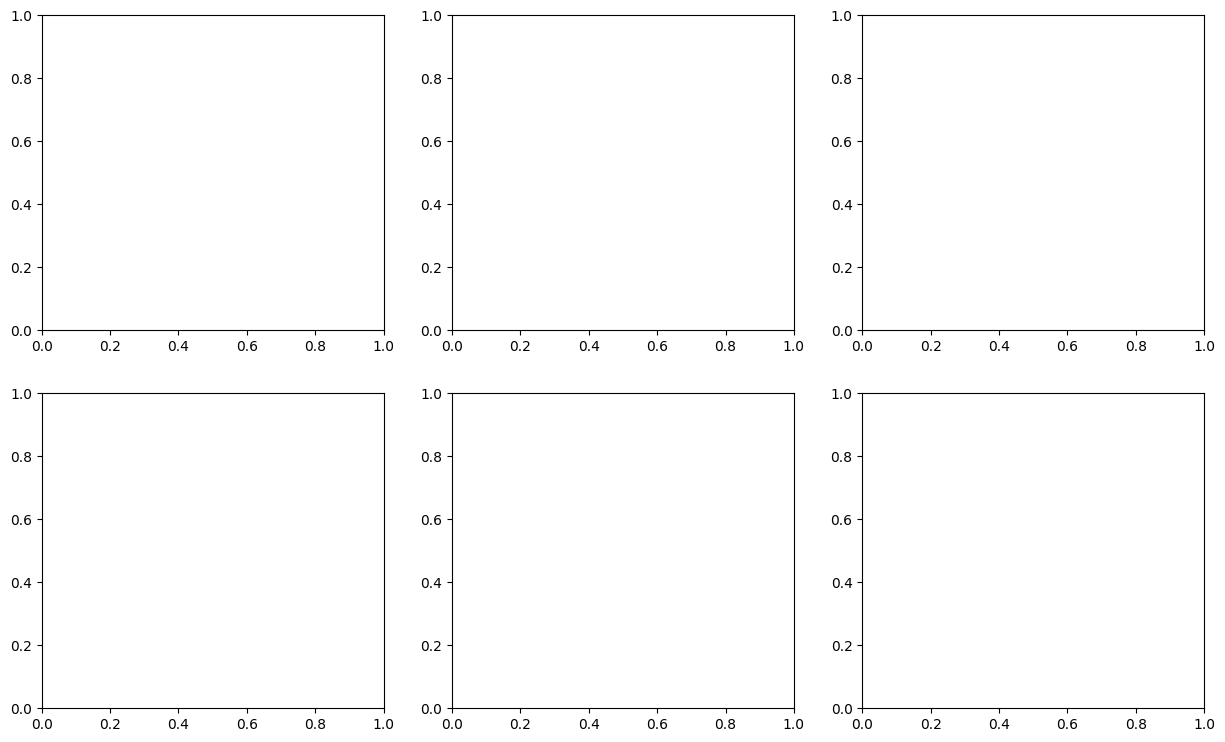

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes[0, 0].imshow(image_original, cmap="gray")
axes[0, 0].set_title("Original - Grayscale")
axes[0, 1].imshow(hog_image_original, cmap="gray")
axes[0, 1].set_title("Original - HOG")
axes[0, 2].hist(hog_original, bins=50)
axes[0, 2].set_title("Original - HOG Distribution")
axes[1, 0].imshow(image_masked, cmap="gray")
axes[1, 0].set_title("Masked - Grayscale")
axes[1, 1].imshow(hog_image_masked, cmap="gray")
axes[1, 1].set_title("Masked - HOG")
axes[1, 2].hist(hog_masked, bins=50)
axes[1, 2].set_title("Masked - HOG Distribution")
plt.tight_layout()
plt.show()

## 3. Özellikleri oluşturma (yalnızca dosyalar yoksa)

**Önemli:** 10.015 görüntünün HOG hesaplaması uzun sürer. Dosyalar zaten kaydedildiyse bu hücre onları yeniden hesaplamaz. Mevcut dosyalara dokunmaz. Yalnızca bir dosya eksikse o matrisi hesaplar ve kaydeder. Bellek sıkışırsa diğer programları kapatıp kernel’i temiz başlatmak gerekebilir.

In [5]:
need_original = not ORIGINAL_FILE.exists()
need_masked = not MASKED_FILE.exists()

if not need_original and not need_masked:
    print("İki HOG matrisi de mevcut; yeniden hesaplama atlandı.")
else:
    # Her matrisi ayrı hesaplayıp kaydediyoruz; iki büyük listeyi aynı anda tutmuyoruz.
    for kind, target in [("Original", ORIGINAL_FILE), ("Masked", MASKED_FILE)]:
        if target.exists():
            print(f"{kind}: dosya zaten mevcut, atlandı.")
            continue
        print(f"{kind} HOG hesaplanıyor...")
        from numpy.lib.format import open_memmap
        matrix = open_memmap(
            target, mode="w+", dtype="float32",
            shape=(len(df), len(hog_original))
        )
        try:
            for i, row in enumerate(df.itertuples(index=False)):
                if kind == "Original":
                    img = preprocess_image(row.image_path, size=IMAGE_SIZE, grayscale=True, normalize=False)
                else:
                    img, _ = preprocess_with_mask(row.image_path, row.mask_path, size=IMAGE_SIZE, grayscale=True, normalize=False)
                matrix[i] = extract_hog(img, visualize=False).astype(np.float32)
                if (i + 1) % 1000 == 0 or i + 1 == len(df):
                    print(f"{kind}: {i+1}/{len(df)}")
            matrix.flush()
        except Exception:
            del matrix
            # Yarım yazılan dosyayı sonraki sefer tam veri sanmamak için temizle.
            target.unlink(missing_ok=True)
            raise
        del matrix
        gc.collect()
        print(f"Kaydedildi: {target.name}")

İki HOG matrisi de mevcut; yeniden hesaplama atlandı.


## 4. Etiketleri ve görüntü kimliklerini güvenli string tipinde kaydetme

Nesne (`object`) tipinden kaynaklanan `allow_pickle=False` hatası oluşmaması için Unicode dizisi kullanıyoruz. `df` satır sırası ile HOG üretim sırası aynıdır.

In [6]:
y = np.asarray(df["label"].astype(str).tolist(), dtype="U10")
image_ids = np.asarray(df["image"].astype(str).tolist(), dtype="U64")
np.save(LABELS_FILE, y, allow_pickle=False)
np.save(IDS_FILE, image_ids, allow_pickle=False)
print("Etiketler:", y.shape, y.dtype)
print("Kimlikler:", image_ids.shape, image_ids.dtype)

Etiketler: (10015,) <U10
Kimlikler: (10015,) <U64


## 5. Kaydedilen dosyaları düşük RAM kullanımıyla açıp doğrulama

In [7]:
X_original = np.load(ORIGINAL_FILE, mmap_mode="r")
X_masked = np.load(MASKED_FILE, mmap_mode="r")
y_check = np.load(LABELS_FILE, allow_pickle=False)
ids_check = np.load(IDS_FILE, allow_pickle=False)

expected_shape = (len(df), len(hog_original))
assert X_original.shape == X_masked.shape == expected_shape
assert X_original.dtype == X_masked.dtype == np.float32
assert np.array_equal(y_check, y)
assert np.array_equal(ids_check, image_ids)
assert np.isfinite(X_original[0]).all() and np.isfinite(X_masked[0]).all()
print("Original:", X_original.shape)
print("Masked:", X_masked.shape)
print("Etiket:", y_check.shape)
print("İlk görüntü kontrolü başarılı.")
print("Random Forest'a geçerken dosyaları mmap_mode='r' ile açabilirsiniz.")

NameError: name 'hog_original' is not defined

## 6. İsteğe bağlı ses bildirimi (Windows)

In [ ]:
import winsound

winsound.Beep(300, 3000)
print("Ses testi tamamlandı.")